# 00 · Preparación y limpieza de datos

**Objetivo.** Transformar lo que recolectaron los scrapers (`datos/crudos/`) en datos limpios y listos para los cinco experimentos (`datos/limpios/`), y fijar una única partición entrenamiento / validación / prueba que todos los experimentos comparten.

| Entrada (`datos/crudos/`) | Scraper que la generó |
|---|---|
| `letterboxd.db` — 878 películas mexicanas y 710 mil reseñas | `scrapers/letterboxd_scraper` (`recolectar`, `sinopsis`) |
| `historial_3_a_4.db`, `historial_min5.db` — películas recientes de cada usuario, con estrellas y *like* | `scrapers/user_films_scraper.py` |
| `imdb_movies.csv` — 757 mil títulos de IMDb con géneros | descarga de IMDb |
| `sinopsis_imdb.csv` — sinopsis (es/en) de esos títulos vía TMDb | `scrapers/letterboxd_scraper` (`sinopsis-imdb`) |

| Salida (`datos/limpios/`) | Para qué |
|---|---|
| `catalogo_mx.parquet` | películas recomendables, con metadatos y sinopsis limpias |
| `interacciones_g34.parquet`, `interacciones_g5.parquet` | matriz usuario × película de cada grupo + partición |
| `items_contenido.parquet` | sinopsis limpias de todas las películas de los historiales (contenido / embeddings) |
| `resenas_sentimiento.parquet` | reseñas en español limpias de los usuarios de los experimentos (BETO, JEV) |
| `resenas_afinado_beto.parquet` | reseñas en español de **otros** usuarios (afinado opcional de BETO, sin fuga de datos) |

In [1]:
# --- Configuración del entorno ---------------------------------------------
# En la Mac no hay que cambiar nada. En Colab u otro servidor: sube la carpeta
# TT_Recomendador_Cine_Mexicano (basta con src/ y datos/limpios/) y descomenta:
# from google.colab import drive
# drive.mount('/content/drive')
# import os; os.environ['TT_RAIZ'] = '/content/drive/MyDrive/TT_Recomendador_Cine_Mexicano'

import os, sys, warnings
from pathlib import Path
RAIZ = Path(os.environ.get('TT_RAIZ', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
os.environ['TT_RAIZ'] = str(RAIZ)
sys.path.insert(0, str(RAIZ / 'src'))
warnings.filterwarnings('ignore', category=FutureWarning)
print('Raíz del proyecto:', RAIZ)

Raíz del proyecto: /Users/irving/Documents/TrabajoTerminal/TT_Recomendador_Cine_Mexicano


In [2]:
import json, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recomendador import rutas, limpieza, preparacion

pd.set_option('display.max_colwidth', 120)
SALIDA = rutas.carpeta_resultados('00_datos')

## 1. Fuentes crudas

Conteos directos sobre las bases que dejaron los scrapers. Las reseñas se recolectaron de `letterboxd.com/film/<slug>/reviews/` (respetando `robots.txt`); los historiales, de `letterboxd.com/<usuario>/films/` para una muestra aleatoria de 10 mil usuarios por grupo, elegidos según cuántas películas mexicanas distintas habían reseñado.

In [3]:
with sqlite3.connect(rutas.CRUDOS / 'letterboxd.db') as con:
    crudo = pd.read_sql("""
        SELECT COUNT(*) AS resenas, COUNT(DISTINCT usuario) AS usuarios,
               COUNT(DISTINCT pelicula_slug) AS peliculas_con_resenas,
               SUM(calificacion IS NOT NULL) AS con_estrellas, SUM(idioma = 'es') AS en_espanol
        FROM resenas""", con)
    idiomas = pd.read_sql("SELECT COALESCE(NULLIF(idioma, ''), '(sin etiqueta)') AS idioma, COUNT(*) AS resenas "
                          "FROM resenas GROUP BY 1 ORDER BY 2 DESC LIMIT 8", con)
display(crudo)
display(idiomas)

filas = []
for grupo, info in rutas.GRUPOS.items():
    with sqlite3.connect(rutas.CRUDOS / info['historial']) as con:
        h = pd.read_sql("SELECT COUNT(*) AS filas, COUNT(DISTINCT usuario) AS usuarios, "
                        "COUNT(DISTINCT pelicula_slug) AS peliculas, SUM(calificacion IS NOT NULL) AS con_estrellas, "
                        "SUM(\"like\") AS likes FROM historial_usuario", con)
        e = pd.read_sql("SELECT estado, COUNT(*) AS n FROM usuarios_procesados GROUP BY estado", con)
    filas.append(h.assign(grupo=info['nombre'], **{f'perfil_{k}': v for k, v in zip(e.estado, e.n)}))
display(pd.concat(filas).set_index('grupo'))

,resenas,usuarios,peliculas_con_resenas,con_estrellas,en_espanol
0,710045,340692,868,673224,309577


,idioma,resenas
0,es,309577
1,en,193753
2,(sin etiqueta),124960
3,pt,24913
4,fr,8014
5,it,4273
6,de,4088
7,tl,3103


,filas,usuarios,peliculas,con_estrellas,likes,perfil_completo,perfil_parcial,perfil_vacio
grupo,,,,,,,,
Usuarios con 3 a 4 películas mexicanas reseñadas,1616188,19790,72114,1467945,593651,2831,16959,20
Usuarios con 5 o más películas mexicanas reseñadas,1688846,19784,67660,1557628,641637,1373,18411,26


**Lectura.** Los historiales casi siempre están *parciales*: Letterboxd sirve sin reto de Cloudflare solo la primera página de `/films/` (72 películas, las más recientes), así que el historial es una ventana reciente del gusto del usuario, no su vida completa. Esto se documenta como limitación.

## 2. Limpieza de texto

La limpieza depende de quién va a leer el texto:

| Regla | BETO (`texto_beto`) | LLM JEV (`texto_llm`) | Embeddings / TF-IDF (`sinopsis`) |
|---|---|---|---|
| Normalización Unicode NFC, espacios raros | ✔ | ✔ | ✔ |
| Entidades y etiquetas HTML, URLs | se quitan | se quitan | se quitan |
| Menciones `@usuario`; `#hashtag` → `hashtag` | ✔ | ✔ | — |
| Letras repetidas (`buenísimaaaaa` → `buenísimaaa`), signos (`!!!!!` → `!!!`) | ✔ | ✔ | — |
| Saltos de línea → espacio | ✔ | ✔ | ✔ |
| Emojis | se traducen a palabra (😭 → *llorando*); el resto se quita | se conservan | — |
| Créditos ("Written by…"), sinopsis entre comillas | — | — | se quitan |
| Sinopsis de relleno o genéricas ("Mexican feature film", textos repetidos en ≥3 películas, < 40 caracteres) | — | — | se descartan |
| Minúsculas, acentos, *stopwords* | **no** (el tokenizador los usa) | **no** | solo dentro de TF-IDF |

¿Por qué traducir emojis para BETO? Su vocabulario no los contiene: los convierte en `[UNK]` y se pierde la carga emocional. El LLM sí los entiende, por eso para él se conservan.

In [4]:
with sqlite3.connect(rutas.CRUDOS / 'letterboxd.db') as con:
    muestra = pd.read_sql("SELECT texto FROM resenas WHERE idioma = 'es' ORDER BY RANDOM() LIMIT 20000", con).texto

patrones = {'emojis': r'[\U0001F300-\U0001FAFF☀-➿]', 'saltos de línea': r'\n', 'letras repetidas (4+)': r'([^\W\d_])\1{3,}',
            'URLs': r'https?://', 'HTML': r'<[^>]+>', 'menciones': r'(?<!\w)@\w+', 'hashtags': r'#\w+'}
ruido = pd.Series({k: muestra.str.contains(v, regex=True).mean() for k, v in patrones.items()}, name='% de reseñas')
display((ruido * 100).round(2).to_frame())

con_ruido = muestra[muestra.str.contains(r'[\U0001F300-\U0001FAFF]|\n|([^\W\d_])\1{3,}', regex=True)].head(6)
display(pd.DataFrame({'original': con_ruido.values,
                      'texto_beto': con_ruido.map(lambda t: limpieza.limpiar_resena(t, 'texto')).values,
                      'texto_llm': con_ruido.map(lambda t: limpieza.limpiar_resena(t, 'conservar')).values}))

/var/folders/1q/p88v1jyx5018wll4jctmflf80000gn/T/ipykernel_58321/2708389.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ruido = pd.Series({k: muestra.str.contains(v, regex=True).mean() for k, v in patrones.items()}, name='% de reseñas')


,% de reseñas
emojis,9.26
saltos de línea,18.14
letras repetidas (4+),2.38
URLs,0.02
HTML,0.00
menciones,0.02
hashtags,0.38


/var/folders/1q/p88v1jyx5018wll4jctmflf80000gn/T/ipykernel_58321/2708389.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  con_ruido = muestra[muestra.str.contains(r'[\U0001F300-\U0001FAFF]|\n|([^\W\d_])\1{3,}', regex=True)].head(6)


,original,texto_beto,texto_llm
0,Y acariciar su pene 🤩\n\nPelícula femcell q fuera de pedos sí está bien chistosa,Y acariciar su pene increíble Película femcell q fuera de pedos sí está bien chistosa,Y acariciar su pene 🤩 Película femcell q fuera de pedos sí está bien chistosa
1,"María Novaro > Cuarón\n\nA partir de esta reseña (02/01/2025), revalorizo el uso del corazón en letterboxd y lo rese...","María Novaro > Cuarón A partir de esta reseña (02/01/2025), revalorizo el uso del corazón en letterboxd y lo reservo...","María Novaro > Cuarón A partir de esta reseña (02/01/2025), revalorizo el uso del corazón en letterboxd y lo reservo..."
2,"Mientras México tenga gobierno, Luis Estrada podrá seguir extendiendo esta saga 😍","Mientras México tenga gobierno, Luis Estrada podrá seguir extendiendo esta saga me encanta","Mientras México tenga gobierno, Luis Estrada podrá seguir extendiendo esta saga 😍"
3,"que hermoso es el friends to lovers, nada como salir con una persona que te entiende en cada aspecto y en cada una d...","que hermoso es el friends to lovers, nada como salir con una persona que te entiende en cada aspecto y en cada una d...","que hermoso es el friends to lovers, nada como salir con una persona que te entiende en cada aspecto y en cada una d..."
4,animas es de los culeros más culeros del cine y se merecía todo lo que le pasaba.\n\nque bueno fue ver que nadie le ...,animas es de los culeros más culeros del cine y se merecía todo lo que le pasaba. que bueno fue ver que nadie le apl...,animas es de los culeros más culeros del cine y se merecía todo lo que le pasaba. que bueno fue ver que nadie le apl...
5,Vaya sorpresa!!! Este director sabe convidar el drama con toques de comedia y la cultura mexicana. Si se tienen un b...,Vaya sorpresa!!! Este director sabe convidar el drama con toques de comedia y la cultura mexicana. Si se tienen un b...,Vaya sorpresa!!! Este director sabe convidar el drama con toques de comedia y la cultura mexicana. Si se tienen un b...


In [5]:
ejemplos_sinopsis = ['Mexican feature film', 'A young man returns home. (Written by IMDb user)',
                     '"Un grupo de amigos viaja a Oaxaca."', 'No overview found.']
pd.DataFrame({'original': ejemplos_sinopsis,
              'limpia': [limpieza.limpiar_sinopsis(t) for t in ejemplos_sinopsis],
              'informativa': [limpieza.sinopsis_informativa(limpieza.limpiar_sinopsis(t)) for t in ejemplos_sinopsis]})

,original,limpia,informativa
0,Mexican feature film,Mexican feature film,False
1,A young man returns home. (Written by IMDb user),A young man returns home.,False
2,"""Un grupo de amigos viaja a Oaxaca.""",Un grupo de amigos viaja a Oaxaca.,False
3,No overview found.,,False


## 3. Construcción de los datos limpios

`preparacion.preparar()` hace, en orden:

1. **Catálogo mexicano.** Las 878 películas de `letterboxd.db`, con géneros de IMDb (enlazados por `tmdb_id`) y sinopsis limpias. Se prefiere la sinopsis en inglés porque es el idioma común a casi todo el resto del corpus (IMDb/TMDb); se guardan ambas.
2. **Interacciones por grupo.** Para cada usuario se unen *sus reseñas de cine mexicano* (con estrellas y texto) y *su historial general* (estrellas y *like*). Si un par usuario–película aparece en ambos, cuenta una vez y se usa la calificación de la reseña más reciente.
3. **Partición** (semilla 42). Candidatas a prueba: películas mexicanas que el usuario reseñó **y calificó**. Con *n* candidatas: `test = max(1, round(0.2·n))` si *n* ≥ 2; `val` del mismo tamaño si después quedan ≥ 2. Así siempre queda al menos una película mexicana en entrenamiento. Al retirar un par se retira completo (también del historial) para evitar fuga de información.
4. **Sinopsis del historial.** Cada slug de Letterboxd se enlaza con IMDb por título y año (ver `enlazar_slugs_con_imdb`).
5. **Reseñas para sentimiento.** Las reseñas en español de los usuarios de ambos grupos, con las dos versiones limpias del texto; y, aparte, las reseñas en español con estrellas de *otros* usuarios para un afinado opcional de BETO.

In [6]:
reporte = preparacion.preparar()
print(json.dumps(reporte, ensure_ascii=False, indent=1, default=int))

{
 "semilla": 42,
 "catalogo": {
  "peliculas": 878,
  "con_genero_imdb": 832,
  "con_sinopsis_informativa": 878,
  "paises_incluye_mexico": 855
 },
 "g34": {
  "usuarios": 19790,
  "peliculas": 72240,
  "interacciones": 1659339,
  "interacciones_mx": 95799,
  "interacciones_mx_con_resena": 66339,
  "con_calificacion": 1508304,
  "particion": {
   "train": 1621906,
   "test": 19098,
   "val": 18335
  },
  "usuarios_con_test": 19098,
  "test_relevantes_>=3.5": 11276
 },
 "g5": {
  "usuarios": 19784,
  "peliculas": 67786,
  "interacciones": 1844900,
  "interacciones_mx": 239442,
  "interacciones_mx_con_resena": 198139,
  "con_calificacion": 1705859,
  "particion": {
   "train": 1770555,
   "test": 37225,
   "val": 37120
  },
  "usuarios_con_test": 19426,
  "test_relevantes_>=3.5": 20859
 },
 "items_contenido": {
  "peliculas": 98798,
  "enlazadas_imdb": 54248,
  "con_sinopsis_informativa": 51466,
  "idioma_sinopsis": {
   "en": 50963,
   "es": 305,
   "otra": 198
  }
 },
 "resenas_sentim

## 4. Descripción de los datos limpios

In [7]:
cat = pd.read_parquet(rutas.LIMPIOS / 'catalogo_mx.parquet')
filas = []
inters = {}
for grupo, info in rutas.GRUPOS.items():
    inter = pd.read_parquet(rutas.LIMPIOS / f'interacciones_{grupo}.parquet')
    inters[grupo] = inter
    mx = inter[inter.es_mx]
    por_usuario = mx.groupby('usuario').size()
    filas.append({
        'grupo': info['nombre'], 'usuarios': inter.usuario.nunique(), 'películas': inter['item'].nunique(),
        'interacciones': len(inter), 'densidad (%)': 100 * len(inter) / (inter.usuario.nunique() * inter['item'].nunique()),
        'interacciones con cine MX': len(mx), 'películas MX por usuario (mediana)': por_usuario.median(),
        'películas del catálogo vistas': mx['item'].nunique(), '% con estrellas': 100 * inter.calificacion.notna().mean(),
        'test': (inter.particion == 'test').sum(), 'test relevantes (≥3.5★)': ((inter.particion == 'test') & (inter.calificacion >= 3.5)).sum(),
        'val': (inter.particion == 'val').sum(),
    })
resumen_grupos = pd.DataFrame(filas).set_index('grupo').T
resumen_grupos.to_csv(SALIDA / 'resumen_grupos.csv')
resumen_grupos

grupo,Usuarios con 3 a 4 películas mexicanas reseñadas,Usuarios con 5 o más películas mexicanas reseñadas
usuarios,1.979000e+04,1.978400e+04
películas,7.224000e+04,6.778600e+04
interacciones,1.659339e+06,1.844900e+06
densidad (%),1.160678e-01,1.375684e-01
interacciones con cine MX,9.579900e+04,2.394420e+05
películas MX por usuario (mediana),4.000000e+00,9.000000e+00
películas del catálogo vistas,8.280000e+02,8.610000e+02
% con estrellas,9.089788e+01,9.246349e+01
test,1.909800e+04,3.722500e+04
test relevantes (≥3.5★),1.127600e+04,2.085900e+04


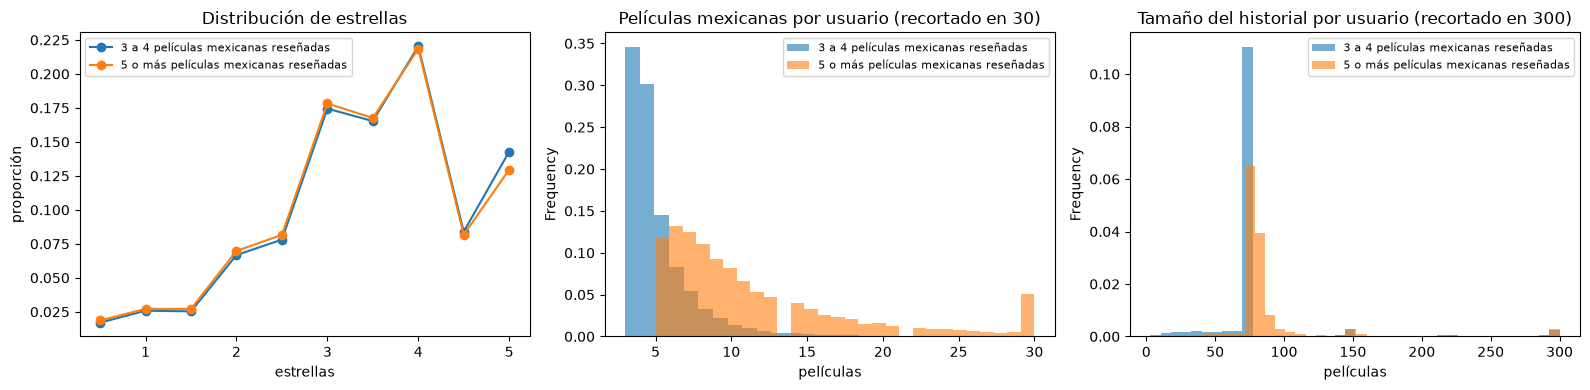

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for grupo, inter in inters.items():
    nombre = rutas.GRUPOS[grupo]['nombre'].replace('Usuarios con ', '')
    inter.calificacion.dropna().value_counts(normalize=True).sort_index().plot(ax=ejes[0], marker='o', label=nombre)
    inter[inter.es_mx].groupby('usuario').size().clip(upper=30).plot.hist(ax=ejes[1], bins=28, alpha=0.6, label=nombre, density=True)
    inter.groupby('usuario').size().clip(upper=300).plot.hist(ax=ejes[2], bins=40, alpha=0.6, label=nombre, density=True)
ejes[0].set(title='Distribución de estrellas', xlabel='estrellas', ylabel='proporción')
ejes[1].set(title='Películas mexicanas por usuario (recortado en 30)', xlabel='películas')
ejes[2].set(title='Tamaño del historial por usuario (recortado en 300)', xlabel='películas')
for e in ejes: e.legend(fontsize=8)
fig.tight_layout(); fig.savefig(SALIDA / 'distribuciones_grupos.png', dpi=130)

In [9]:
# Popularidad del catálogo: pocas películas concentran la mayoría de las interacciones (cola larga)
pop = pd.concat(inters.values()).query('es_mx').groupby('item').size().sort_values(ascending=False)
acumulado = pop.cumsum() / pop.sum()
print(f"El 10 % más visto del catálogo ({int(len(pop)*0.1)} películas) concentra el {acumulado.iloc[int(len(pop)*0.1)]:.0%} de las interacciones.")
display(pop.head(10).rename('interacciones').to_frame().join(cat.set_index('item')[['titulo', 'anio']]))

El 10 % más visto del catálogo (86 películas) concentra el 47% de las interacciones.


,interacciones,titulo,anio
item,,,
i-am-frankelda,4314,I Am Frankelda,2025
like-or-die,4203,Like or Die,2023
mexico-86-2026,3945,Mexico 86,2026
corina-2024,3569,Corina,2024
chicuarotes,3015,Chicuarotes,2019
pedro-paramo-2024,2611,Pedro Páramo,2024
la-cocina-2024,2376,La Cocina,2024
aztec-batman-clash-of-empires,2352,Aztec Batman: Clash of Empires,2025
im-no-longer-here,2333,I'm No Longer Here,2019


## 5. Reseñas para el análisis de sentimiento

Reseñas: 151,516  ·  con estrellas: 96.3%  ·  con emoji traducido: 9.7%
Largo en caracteres: mediana 115, p95 485, máx 808


,resenas,usuarios,estrellas_media
grupo,,,
g34,31644,13143,3.489470
g5,119872,15695,3.359881


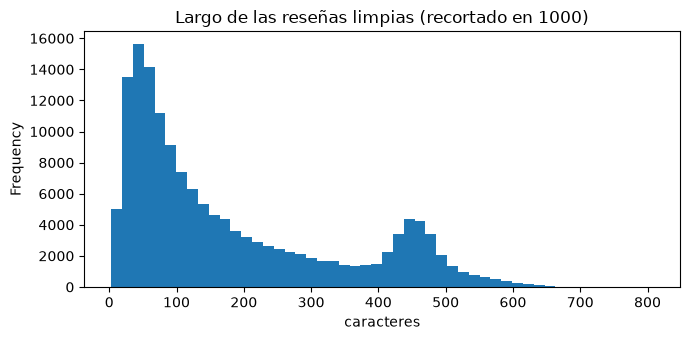

In [10]:
res = pd.read_parquet(rutas.LIMPIOS / 'resenas_sentimiento.parquet')
largo = res.texto_beto.str.len()
print(f"Reseñas: {len(res):,}  ·  con estrellas: {res.calificacion.notna().mean():.1%}  ·  "
      f"con emoji traducido: {(res.texto_beto != res.texto_llm).mean():.1%}")
print(f"Largo en caracteres: mediana {largo.median():.0f}, p95 {largo.quantile(.95):.0f}, máx {largo.max():,}")
display(res.groupby('grupo').agg(resenas=('id', 'size'), usuarios=('usuario', 'nunique'),
                                 estrellas_media=('calificacion', 'mean')))
fig, eje = plt.subplots(figsize=(7, 3.5))
largo.clip(upper=1000).plot.hist(bins=50, ax=eje)
eje.set(title='Largo de las reseñas limpias (recortado en 1000)', xlabel='caracteres')
fig.tight_layout(); fig.savefig(SALIDA / 'largo_resenas.png', dpi=130)

## 6. Sinopsis para el filtrado por contenido y los embeddings

In [11]:
items = pd.read_parquet(rutas.LIMPIOS / 'items_contenido.parquet')
con = items[items.sinopsis != '']
print(f"Películas en algún historial o en el catálogo: {len(items):,}")
print(f"Con sinopsis informativa: {len(con):,} ({len(con)/len(items):.1%})")
print('Idioma de la sinopsis elegida:', con.idioma_sinopsis.value_counts().to_dict())
interacciones = pd.concat(inters.values())
cubiertas = interacciones['item'].isin(con['item']).mean()
print(f"Interacciones cuya película tiene sinopsis: {cubiertas:.1%}")
display(con.sample(5, random_state=1)[['item', 'titulo', 'anio', 'generos', 'sinopsis']])

Películas en algún historial o en el catálogo: 98,798
Con sinopsis informativa: 51,466 (52.1%)
Idioma de la sinopsis elegida: {'en': 50963, 'es': 305, 'otra': 198}


Interacciones cuya película tiene sinopsis: 89.4%


,item,titulo,anio,generos,sinopsis
65018,millionaire-dog,Millionaire Dog,2014.0,"Comedy,Family","Since he won the lottery, Pancho, a Jack Russell Terrier dog, lives a life full of luxury. His personal assistant ma..."
32407,french-cancan,French Cancan,1955.0,"Comedy,Drama,Musical",Nineteenth-century Paris comes vibrantly alive in Jean Renoir’s exhilarating tale of the opening of the world-renown...
3169,jerry-marge-go-large,Jerry & Marge Go Large,2022.0,"Biography,Comedy,Drama",The remarkable true story of how retiree Jerry Selbee discovers a mathematical loophole in the Massachusetts lottery...
121,a-not-so-merry-christmas,A Not So Merry Christmas,2022.0,"Comedy,Fantasy","A curse is placed on grinchy Chuy, who wakes up to find he's lived a full year, but is doomed to remember only Chris..."
24927,88-88-2015,88:88,2015.0,Documentary,"88:88, —:—, flashes, demonstrating those who live in poverty live in suspended time."


## Resumen

* Los dos grupos tienen ~19.8 mil usuarios cada uno y no comparten usuarios.
* El grupo 3–4 aporta en promedio 3.4 reseñas de cine mexicano por usuario; el grupo ≥ 5, 10. Eso es justo lo que se quiere contrastar en los experimentos 1 y 2.
* Las reseñas en español de esos usuarios (≈151 mil) son la entrada de los experimentos 4 (BETO) y 5 (JEV).
* El ~87 % de las interacciones del historial tiene una sinopsis útil para el experimento 3.